# 01 Task and model

**Task.** 8-class modulation recognition on synthetic complex baseband I/Q: 128 samples at 8 samples/symbol, random carrier phase, carrier-frequency offset $\pm1\,\%$ of $f_s$, random timing offset, AWGN at SNR $\in\{0,5,10,15,20\}$ dB. 16 000 train / 4 000 test examples, generated in-repo and deterministic (sha256 below).

**Model.** `TDL-Net`: 2 lines (I, Q) $\to$ L1 ($K=8$, $d=1$) $\to$ L2 ($d=4$) $\to$ L3 ($d=16$) $\to$ RC average pool $\to$ ternary linear $\to$ softmax. Receptive field $1+7\,(1+4+16)=148\ge128$. Trained offline with ternary quantisation-aware training (BitNet b1.58 rule $W_t=\mathrm{clip}(\mathrm{round}(W/\gamma),-1,1)$, $\gamma=\mathrm{mean}|W|$, straight-through estimator).

In [1]:
import json, os, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dlnn.viz import nb, figures
from dlnn.viz.common import TIER_COL, MARKERS, LINESTYLES, TIER_SHORT, INK, conf_matrix

nb.setup()
run = nb.load_run()          # env DLNN_RUN, default out/modrec-w32-full (read-only; the pipeline is NOT rerun here)
cmp = run.cmp
print(f"run {run.dir.name} | model {os.path.basename(cmp['run_meta']['model_file'])} | cascade={run.cascade} | "
      f"tiers {cmp['tiers']} | n_test {cmp['tier_info']['V']['n_examples']}")
from dlnn.data import modrec
ds = modrec.dataset()
print("dataset sha256 regenerated:", ds["sha256"][:16], "| recorded in the run:", cmp["dataset_sha256"][:16], "| identical:", ds["sha256"] == cmp["dataset_sha256"])
print("train", ds["x_train"].shape, "test", ds["x_test"].shape, "classes", modrec.CLASSES)

run final-w32 | model tdlnet_modrec_w32_ternary.npz | cascade=True | tiers ['V', 'E', 'C', 'R'] | n_test 4000


dataset sha256 regenerated: e1b8e74480bdb325 | recorded in the run: e1b8e74480bdb325 | identical: True
train (16000, 2, 128) test (4000, 2, 128) classes ('OOK', 'BPSK', 'QPSK', '8PSK', '16QAM', '2FSK', '4FSK', 'GMSK')


## The eight signal classes (20 dB SNR examples)

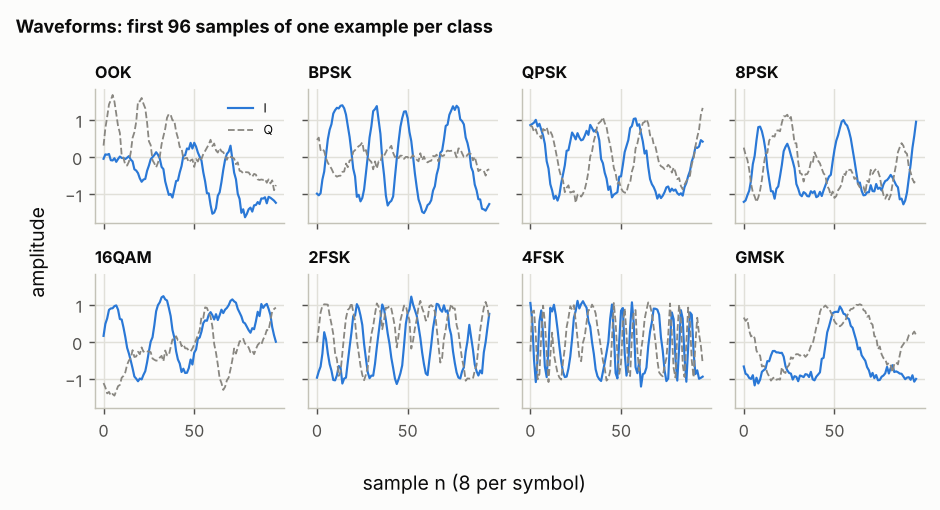

In [2]:
g = modrec.generate(80, snrs=(20,))            # 10 per class, all at 20 dB
x, y = g["x"], g["y"]
cls = list(modrec.CLASSES)
col = TIER_COL["light"]["V"]
fig, axs = plt.subplots(2, 4, figsize=(7.2, 3.8), sharex=True, sharey=True)
for c, ax in enumerate(axs.ravel()):
    e = x[y == c][0]
    ax.plot(e[0, :96], color=col, lw=1.2, label="I"); ax.plot(e[1, :96], color=INK["light"]["muted"], lw=1.0, ls="--", label="Q")
    ax.set_title(cls[c], fontsize=9)
axs[0, 0].legend(fontsize=7); fig.supxlabel("sample n (8 per symbol)"); fig.supylabel("amplitude")
fig.suptitle("Waveforms: first 96 samples of one example per class", x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout(); nb.show_fig(fig)

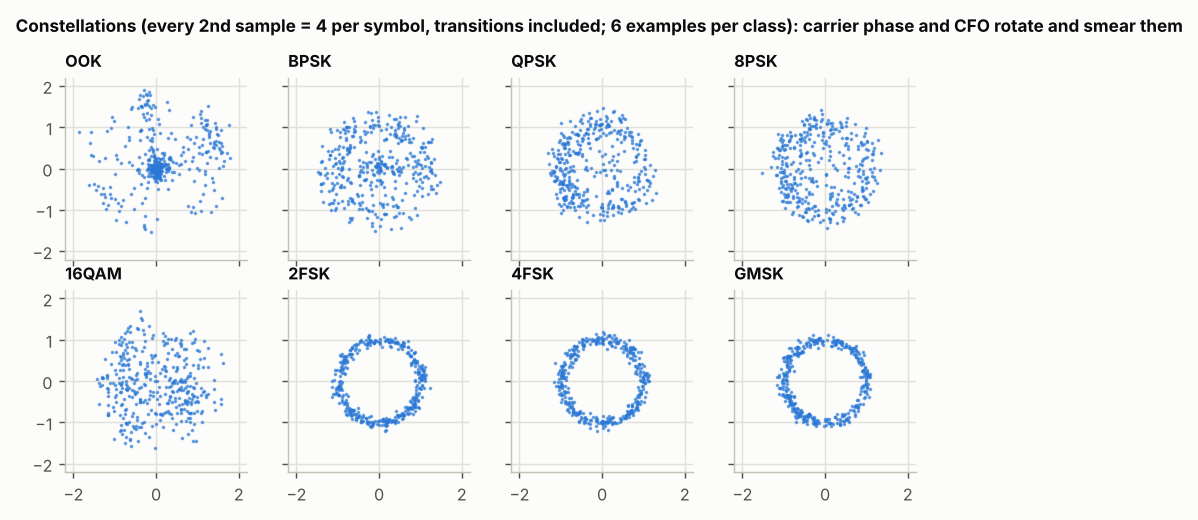

In [3]:
fig, axs = plt.subplots(2, 4, figsize=(7.2, 3.9), sharex=True, sharey=True)
for c, ax in enumerate(axs.ravel()):
    e = x[y == c][:6]
    ax.plot(e[:, 0, ::2].ravel(), e[:, 1, ::2].ravel(), ".", ms=2.0, color=col, alpha=0.6)
    ax.set_title(cls[c], fontsize=9); ax.set_aspect("equal"); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
fig.suptitle("Constellations (every 2nd sample = 4 per symbol, transitions included; 6 examples per class): carrier phase and CFO rotate and smear them", x=0.01, ha="left", fontsize=9.5, fontweight="bold")
fig.tight_layout(); nb.show_fig(fig)

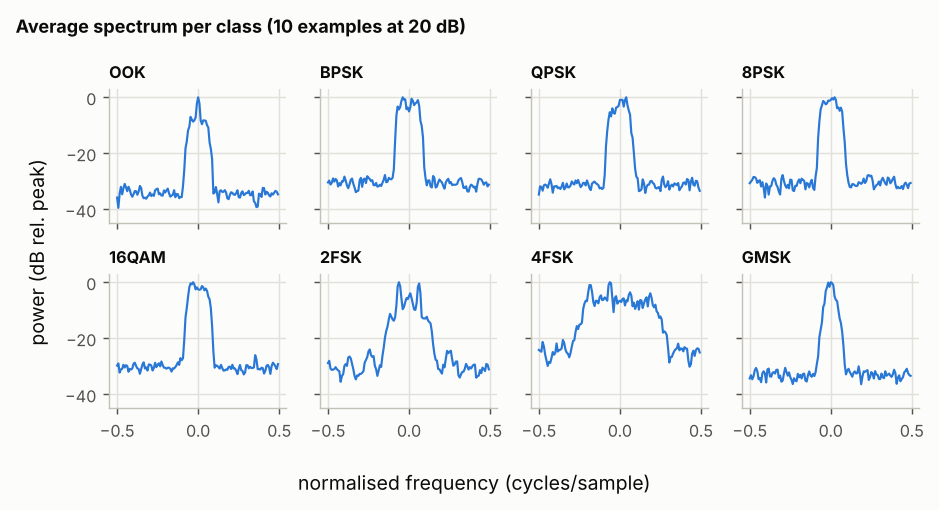

In [4]:
fig, axs = plt.subplots(2, 4, figsize=(7.2, 3.8), sharex=True, sharey=True)
f = np.fft.fftshift(np.fft.fftfreq(128))
for c, ax in enumerate(axs.ravel()):
    z = x[y == c][:, 0] + 1j * x[y == c][:, 1]
    P = np.mean(np.abs(np.fft.fftshift(np.fft.fft(z * np.hanning(128), axis=1), axes=1)) ** 2, axis=0)
    ax.plot(f, 10 * np.log10(P / P.max()), color=col, lw=1.2); ax.set_title(cls[c], fontsize=9); ax.set_ylim(-45, 3)
fig.supxlabel("normalised frequency (cycles/sample)"); fig.supylabel("power (dB rel. peak)")
fig.suptitle("Average spectrum per class (10 examples at 20 dB)", x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout(); nb.show_fig(fig)

## Training report: float32 vs ternary, and width 8 (plan spec) vs width 32 (headline)

In [5]:
rep = {w: json.load(open(nb.ROOT / "models" / f)) for w, f in ((8, "train_report.json"), (32, "train_report_w32.json"))}
rows = ["| width | variant | weights | accuracy (mixed SNR) | accuracy >= 10 dB | train time (s) | note |", "|---|---|---|---|---|---|---|"]
for w in (8, 32):
    r = rep[w]
    rows.append(f"| {w} | float32 | unconstrained | {r['float']['acc']:.4f} | {r['float']['acc_ge10dB']:.4f} | {r['float']['seconds']:.0f} | reference only |")
    note = "plan spec; **misses the 85 % >= 10 dB target, 8PSK = 0 %**" if w == 8 else "**headline model of the demo**"
    rows.append(f"| {w} | ternary | {r['ternary']['n_ternary_weights']} taps | {r['ternary']['acc']:.4f} | {r['ternary']['acc_ge10dB']:.4f} | {r['ternary']['seconds']:.0f} | {note} |")
nb.md("\n".join(rows))
r = rep[32]["recipe"]
print("recipe (both widths):", {k: r[k] for k in ("optimizer", "lr", "schedule", "batch", "epochs", "iq_rotation_aug", "restarts", "soft_frac")})
print("Not the plan recipe (lr 3e-3, 20 epochs underfits badly: float 62 %, ternary 45 %); see docs/build-log-M1.md for everything that was tried.")

| width | variant | weights | accuracy (mixed SNR) | accuracy >= 10 dB | train time (s) | note |
|---|---|---|---|---|---|---|
| 8 | float32 | unconstrained | 0.8465 | 0.8746 | 84 | reference only |
| 8 | ternary | 1152 taps | 0.7348 | 0.7629 | 117 | plan spec; **misses the 85 % >= 10 dB target, 8PSK = 0 %** |
| 32 | float32 | unconstrained | 0.9187 | 0.9546 | 90 | reference only |
| 32 | ternary | 16896 taps | 0.8628 | 0.8912 | 150 | **headline model of the demo** |

recipe (both widths): {'optimizer': 'Adam', 'lr': 0.03, 'schedule': 'cosine', 'batch': 256, 'epochs': 60, 'iq_rotation_aug': True, 'restarts': 1, 'soft_frac': 0.5}
Not the plan recipe (lr 3e-3, 20 epochs underfits badly: float 62 %, ternary 45 %); see docs/build-log-M1.md for everything that was tried.


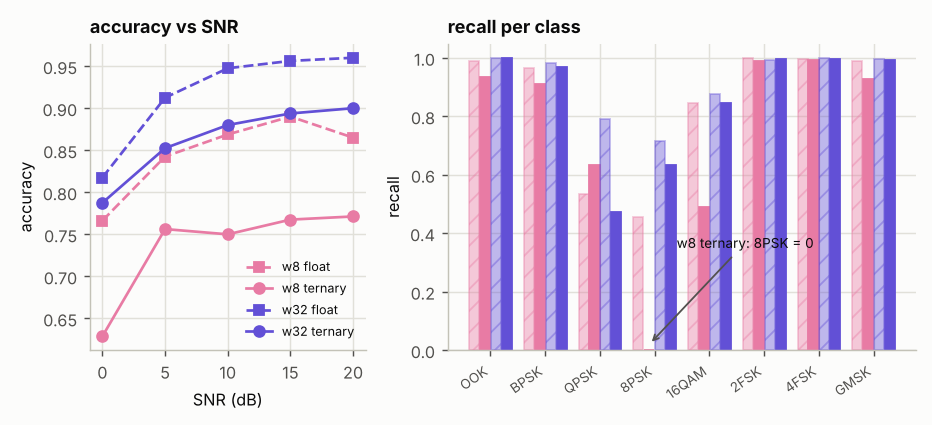

*Solid = ternary, hatched/light = float32; magenta = width 8, violet = width 32 (these are model variants, not the tier colours of the later figures). Width 32 recovers 8PSK to 0.63 recall and 16QAM to 0.84; QPSK stays the hard class (0.47).*

In [6]:
# per-SNR and per-class accuracy of the four trained models (test set, 4000 examples)
SER = [("w8 float", rep[8]["float"], "#e87ba4", "//"), ("w8 ternary", rep[8]["ternary"], "#e87ba4", None),
       ("w32 float", rep[32]["float"], "#6250d6", "//"), ("w32 ternary", rep[32]["ternary"], "#6250d6", None)]
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.3), gridspec_kw={"width_ratios": [1, 1.7]})
ax = axs[0]
for name, r_, c_, h in SER:
    s = sorted(r_["acc_per_snr"], key=int)
    ax.plot([int(k) for k in s], [r_["acc_per_snr"][k] for k in s], marker="o" if h is None else "s", color=c_, ls="-" if h is None else "--", label=name)
ax.set_xlabel("SNR (dB)"); ax.set_ylabel("accuracy"); ax.legend(fontsize=7); ax.set_title("accuracy vs SNR")
ax = axs[1]; w = 0.2
for j, (name, r_, c_, h) in enumerate(SER):
    ax.bar(np.arange(8) + (j - 1.5) * w, [r_["acc_per_class"][c] for c in cls], w * 0.92, color=c_, hatch=h, edgecolor=c_, alpha=1.0 if h is None else 0.4)
ax.set_xticks(range(8)); ax.set_xticklabels(cls, rotation=35, ha="right", fontsize=7.5); ax.set_ylabel("recall"); ax.set_title("recall per class")
ax.annotate("w8 ternary: 8PSK = 0", (3 - 0.5 * w, 0.02), xytext=(3.4, 0.35), fontsize=7.5, arrowprops=dict(arrowstyle="->", color=INK["light"]["sec"]))
fig.tight_layout(); nb.show_fig(fig)
nb.md("*Solid = ternary, hatched/light = float32; magenta = width 8, violet = width 32 (these are model variants, not the tier colours of the later figures). Width 32 recovers 8PSK to 0.63 recall and 16QAM to 0.84; QPSK stays the hard class (0.47).*")

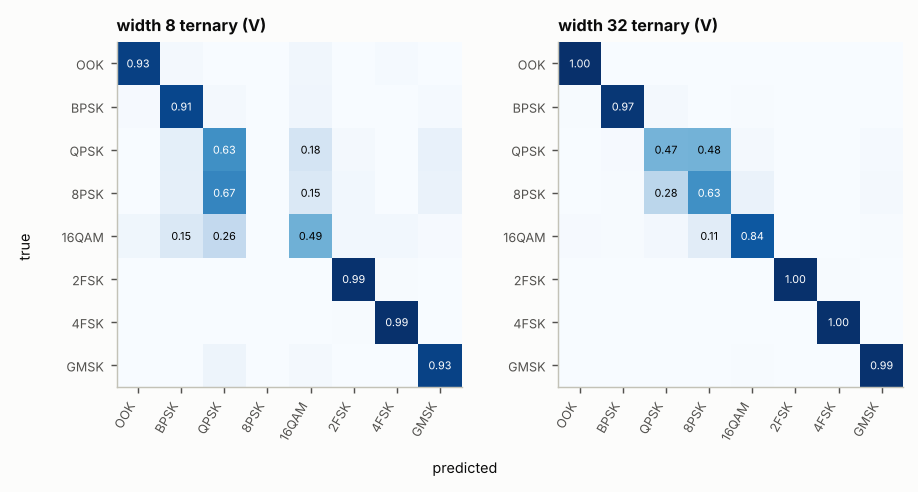

In [7]:
# where the 8PSK collapse goes: confusion matrices of the two ternary models from the stored runs (V tier, test set)
def vconf(name):
    d = nb.ROOT / "out" / name
    if not (d / "tiers" / "V.npz").exists():
        return None
    return conf_matrix(np.load(d / "labels.npy"), np.load(d / "tiers" / "V.npz")["pred"], 8)
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.6))
for ax, name, ttl in zip(axs, ("modrec-w8-full", "modrec-w32-full"), ("width 8 ternary (V)", "width 32 ternary (V)")):
    cm = vconf(name)
    if cm is None:
        ax.axis("off"); ax.text(0.5, 0.5, f"{name} not present", ha="center"); continue
    rn = cm / cm.sum(1, keepdims=True)
    ax.imshow(rn, cmap="Blues", vmin=0, vmax=1); ax.grid(False); ax.set_title(ttl, fontsize=9)
    ax.set_xticks(range(8)); ax.set_xticklabels(cls, rotation=60, ha="right", fontsize=7); ax.set_yticks(range(8)); ax.set_yticklabels(cls, fontsize=7)
    for i in range(8):
        for j in range(8):
            if rn[i, j] >= 0.1:
                ax.text(j, i, f"{rn[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if rn[i, j] > 0.55 else "black")
fig.supxlabel("predicted", fontsize=8); fig.supylabel("true", fontsize=8); fig.tight_layout(); nb.show_fig(fig)

## Weights: ternary tap polarity vs the float baseline

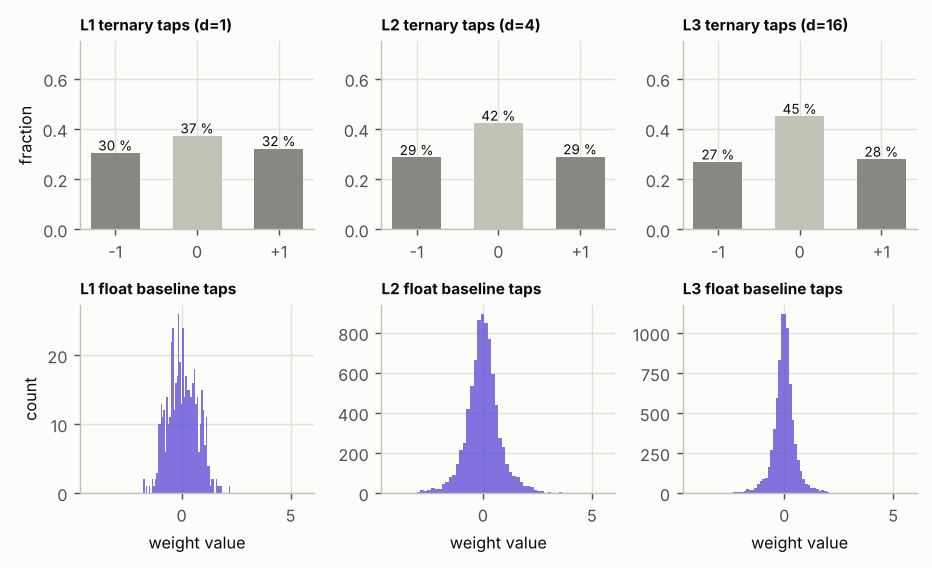

width 32:  16896 ternary conv taps; nonzero fractions [0.63, 0.58, 0.55]
width 8 :  1152 ternary conv taps; nonzero fractions [0.65, 0.53, 0.42]
per-layer V_sat (amplifier saturation): [1.44, 3.03, 3.33] | per-layer gain g (all ones: no per-line scale): [1.0, 1.0, 1.0]


In [8]:
from dlnn.model.export import load_float_model
from dlnn.model.npz import load_model
mt, mf = load_model(nb.ROOT / "models" / "tdlnet_modrec_w32_ternary.npz"), load_float_model(nb.ROOT / "models" / "tdlnet_modrec_w32_float.npz")
m8 = load_model(nb.ROOT / "models" / "tdlnet_modrec_ternary.npz")
fig, axs = plt.subplots(2, 3, figsize=(7.2, 4.4), sharex="row")
for l in range(3):
    W = mt.layers[l].W
    cnt = [(W == -1).mean(), (W == 0).mean(), (W == 1).mean()]
    axs[0, l].bar(["-1", "0", "+1"], cnt, color=["#898781", "#c3c2b7", "#898781"], width=0.6)
    for xx, v in zip(range(3), cnt):
        axs[0, l].text(xx, v + 0.01, f"{100 * v:.0f} %", ha="center", fontsize=7.5)
    axs[0, l].set_ylim(0, 0.75); axs[0, l].set_title(f"L{l + 1} ternary taps (d={mt.layers[l].dilation})", fontsize=8.5)
    axs[1, l].hist(mf.layers[l].W.ravel(), bins=60, color="#6250d6", alpha=0.8)
    axs[1, l].set_title(f"L{l + 1} float baseline taps", fontsize=8.5); axs[1, l].set_xlabel("weight value")
axs[0, 0].set_ylabel("fraction"); axs[1, 0].set_ylabel("count")
fig.tight_layout(); nb.show_fig(fig)
print("width 32: ", mt.n_ternary_weights, "ternary conv taps; nonzero fractions", [round(float((l.W != 0).mean()), 2) for l in mt.layers])
print("width 8 : ", m8.n_ternary_weights, "ternary conv taps; nonzero fractions", [round(float((l.W != 0).mean()), 2) for l in m8.layers])
print("per-layer V_sat (amplifier saturation):", [round(l.vsat, 2) for l in mt.layers], "| per-layer gain g (all ones: no per-line scale):", [float(l.gain.mean()) for l in mt.layers])

**Reading this.** A ternary tap has three states; about 37-45 % of them are *no tap at all* (width 32) (a free sparsity), the rest split evenly between the two polarities. The float baseline is the same topology with free real taps: it is better (0.919 vs 0.863 mixed-SNR) and is shown only as the reference the ternary constraint is judged against.

Honest limits: the width-8 net of the plan (1 216 taps) is a capacity-limited model on this task; width 32 (16 896 taps) is what the four-tier comparison uses.